# Filling the missing values: four methods compared

## Why this notebook exists

Our project question: **can we predict which students want to change their job (`job_change`)?**

To answer it we need a model later, and a model can't work with gaps. So first we have to fill the missing values. The question of this notebook is: **with what?**

The overview notebook (`missing_values_overview.ipynb`) already prepared this decision. Its main findings and what we do with them here:

| Finding in the overview notebook | What it means for this notebook |
|---|---|
| 42 % of the students have at least one gap | dropping rows is not an option, we have to fill |
| major_discipline is mostly empty for students without a degree | not a real gap, we fill it with a fixed rule ("No Major") |
| company information is not missing at random: often there is probably no employer | putting a company size into these gaps would invent something |
| company information is missing twice as often for job changers (50 % vs. 25 %) | the gap itself says something about job_change, a good method should keep that |

## The problem: we can't check the filled values directly

If we knew the true values, we would simply compare them with the filled ones. But they are missing, that's the whole point. So we check every method in two indirect ways:

1. **Check 1: is it plausible?** (section 5) What does each method put into the gaps, and does that fit what we know about these students?
2. **Check 2: is it useful?** (section 6) We fill the data for one reason: to predict job_change later. So we train the same simple model on every filled version. If a method throws away useful information, the model gets worse.

In section 7 we choose the method that does well in both checks.

The data from week 2 (`customer_train_typed.pkl`) is only read, never changed. At the end we save a prepared dataset in the week 3 folder.

## 1. Loading the data

Same start as in the other notebooks, with three changes:

- `student_id` is only a number without meaning, and `city` has 123 values that would blow up the model. `city_development_index` already describes the city, so we leave out both columns (same decision as in `knn_methode.ipynb`).
- `gender` is left out completely. A model that predicts job changes should not use a person's gender (fairness, lecture chapter 1), so we don't fill it and don't use it.
- `city_development_index` is stored as `float16` to save memory. For calculations we turn it back into `float64`, otherwise pandas shows overflow warnings.

`X` holds the features, `y` the target (1 = wants to change the job).

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # needed before IterativeImputer can be imported
from sklearn.impute import KNNImputer, IterativeImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

df = pd.read_pickle("../week 2/customer_train_typed.pkl")
df["city_development_index"] = df["city_development_index"].astype("float64")

X = df.drop(columns=["student_id", "city", "gender", "job_change"])
y = df["job_change"].astype(int)

X.isna().sum()

city_development_index       0
relevant_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
last_new_job               423
training_hours               0
dtype: int64

## 2. A strategy for every column

From the overview notebook:

| Column | Missing | What we know | Plan |
|---|---|---|---|
| company_type | 32.0 % | gap = information (often no employer), missing twice as often for job changers | compare methods |
| company_size | 31.0 % | same as company_type | compare methods |
| major_discipline | 14.7 % | mostly students without a degree, they simply have no major | fixed rule first, then compare |
| education_level, last_new_job, enrolled_university | about 2 % | small, weak link to the target | compare methods |
| experience | 0.3 % | no link found | compare methods |

### The fixed rule for major_discipline

Students who only went to school (Primary School or High School) can't have a study major. For them the right value is not "unknown" but "No Major", a category that already exists in the data.

This rule doesn't learn anything from the data, it's just a fact about the question. That's why we can apply it to the whole dataset before the split without causing data leakage.

In [33]:
school_only = X["education_level"].isin(["Primary School", "High School"])
rule = school_only & X["major_discipline"].isna()

X.loc[rule, "major_discipline"] = "No Major"

print(f"Filled by the rule: {rule.sum():,}")
print(f"major_discipline still missing: {X['major_discipline'].isna().sum():,}")

Filled by the rule: 2,325
major_discipline still missing: 488


2,325 of the 2,813 gaps are gone. The remaining 488 are mostly students whose education level is missing too, so the rule can't decide for them. They are filled like the other columns.

## 3. Train/test split

We split before filling anything. The methods in section 4 learn something from the data (the most common value, the nearest neighbours, a regression). They may only learn from the training data, otherwise information from the test data leaks into the training (lecture, chapter 3).

The test set is not used in this notebook at all. We keep it for the final model later. All comparisons run on the training data with cross-validation.

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(X_train.shape, X_test.shape)

(15326, 10) (3832, 10)


## 4. The four methods

| Method | Idea | Type (lecture, chapter 2a) |
|---|---|---|
| **mode** | every gap gets the most common value of its column | simple |
| **unknown** | the big columns get their own category "Unknown", the small ones the most common value | simple, keeps the information "missing" |
| **knn** | look for the 5 most similar students and take their value | donor-based |
| **mice** | predict every column with gaps from the other columns, repeat until the values stop changing | model-based |

Every method is a function that gets a training part and a test part and returns both filled. It always learns from the training part only and then applies the same values to the test part.

### mode

`mode()[0]` is the most common value. It is calculated on the training part and then used for both parts.

In [35]:
cat_cols = list(X.select_dtypes("category").columns)
num_cols = ["city_development_index", "training_hours", "relevant_experience"]


def fill_mode(train, test, columns):
    train, test = train.copy(), test.copy()
    for col in columns:
        most_common = train[col].mode()[0]
        train[col] = train[col].fillna(most_common)
        test[col] = test[col].fillna(most_common)
    return train, test

### unknown

For the three big columns the gap becomes its own category. Two details:

- The columns are of type `category`, so "Unknown" has to be added as an allowed value first (`add_categories`), otherwise `fillna` fails.
- company_size is ordered (`<10` < `10-49` < ...). "Unknown" has no place in that order, so we remove the order with `as_unordered()`.

The small columns get the most common value, with so few gaps the method hardly matters there.

In [36]:
big_cols = ["company_type", "company_size", "major_discipline"]
small_cols = [col for col in cat_cols if col not in big_cols]


def fill_unknown(train, test):
    train, test = train.copy(), test.copy()
    for col in big_cols:
        for data in [train, test]:
            data[col] = data[col].cat.as_unordered().cat.add_categories("Unknown").fillna("Unknown")
    return fill_mode(train, test, small_cols)

### knn and mice

`KNNImputer` and `IterativeImputer` (the scikit-learn version of MICE) only work with numbers. So the function does the same steps as the DataCamp course:

1. **Categories to numbers:** `cat.codes` gives every category its position (for `education_level`: Primary School = 0, High School = 1, ...). Missing values get -1, which we turn back into NaN.
2. **Scale to 0 to 1:** KNN measures distances. Without scaling, `training_hours` (up to 336) would decide everything and a code like 0, 1, 2 would hardly count. `MinMaxScaler` ignores the NaN values while learning.
3. **Fill:** the imputer learns on the training part and fills both parts.
4. **Back to categories:** undo the scaling, round to the nearest whole code (the imputers return values like 2.4) and turn the codes back into categories.

One weak point: for columns without an order (company_type, major_discipline) the codes are only labels. company_type is coded alphabetically, so "NGO" = 2 sits between "Funded Startup" = 1 and "Other" = 3, and that distance means nothing. The DataCamp course does it the same way, but we should keep it in mind when reading the results.

In [37]:
def fill_with_model(imputer, train, test):
    columns = cat_cols + num_cols

    def to_numbers(data):
        numbers = data[columns].copy()
        for col in cat_cols:
            numbers[col] = data[col].cat.codes.replace(-1, np.nan)
        return numbers.astype(float)

    # learn the scaling and the imputer on the training part only
    scaler = MinMaxScaler()
    train_scaled = scaler.fit_transform(to_numbers(train))
    test_scaled = scaler.transform(to_numbers(test))

    train_filled = scaler.inverse_transform(imputer.fit_transform(train_scaled))
    test_filled = scaler.inverse_transform(imputer.transform(test_scaled))

    # round the codes and turn them back into categories
    results = []
    for data, filled in [(train, train_filled), (test, test_filled)]:
        data = data.copy()
        filled = pd.DataFrame(filled, columns=columns, index=data.index)
        for col in cat_cols:
            highest_code = len(data[col].cat.categories) - 1
            codes = filled[col].round().clip(0, highest_code).astype(int)
            data[col] = pd.Categorical.from_codes(codes, dtype=data[col].dtype)
        results.append(data)

    return results[0], results[1]

One function to call any of the four methods by name, so the comparison later can run in a loop:

In [38]:
methods = ["mode", "unknown", "knn", "mice"]


def impute(method, train, test):
    if method == "mode":
        return fill_mode(train, test, cat_cols)
    if method == "unknown":
        return fill_unknown(train, test)
    if method == "knn":
        return fill_with_model(KNNImputer(n_neighbors=5), train, test)
    if method == "mice":
        return fill_with_model(IterativeImputer(max_iter=10, random_state=42), train, test)

Quick check: after every method there must be no gap left. KNN takes a few seconds, because it compares every incomplete row with all training rows.

In [39]:
filled = {}

for method in methods:
    train_filled, test_filled = impute(method, X_train, X_test)
    print(f"{method}: missing after filling: train {train_filled.isna().sum().sum()}, "
          f"test {test_filled.isna().sum().sum()}")
    filled[method] = train_filled

mode: missing after filling: train 0, test 0
unknown: missing after filling: train 0, test 0
knn: missing after filling: train 0, test 0
mice: missing after filling: train 0, test 0


## 5. Check 1: is it plausible?

We look at company_size, the column with the most gaps besides company_type. The table compares:

- **known values:** the company sizes of the students where company_size is filled in
- **mode, unknown, knn, mice:** which sizes each method put into the gaps

What we expect from the overview notebook: many of the students with a gap probably have no employer at all. A method that puts a concrete company size into every gap invents a company for them.

`astype(str)` turns the categories into plain text, so the columns can be put side by side even though only the "unknown" version has the category "Unknown". `reindex(order)` sorts the rows from small to big companies.

In [40]:
was_missing = X_train["company_size"].isna()

shares = {
    "known values": X_train.loc[~was_missing, "company_size"].astype(str).value_counts(normalize=True),
}
for method in methods:
    shares[method] = filled[method].loc[was_missing, "company_size"].astype(str).value_counts(normalize=True)

# all sizes in their natural order, "Unknown" at the end
order = list(X["company_size"].cat.categories) + ["Unknown"]

comparison = (pd.DataFrame(shares).reindex(order).fillna(0) * 100).round(1)
comparison

,known values,mode,unknown,knn,mice
company_size,,,,,
<10,9.8,0.0,0.0,0.0,0.0
10-49,11.1,0.0,0.0,6.3,0.1
50-99,23.4,100.0,0.0,25.2,1.8
100-499,19.7,0.0,0.0,33.0,78.0
500-999,6.5,0.0,0.0,23.0,19.9
1000-4999,9.7,0.0,0.0,9.9,0.2
5000-9999,4.2,0.0,0.0,2.4,0.0
10000+,15.5,0.0,0.0,0.2,0.0
Unknown,0.0,0.0,100.0,0.0,0.0


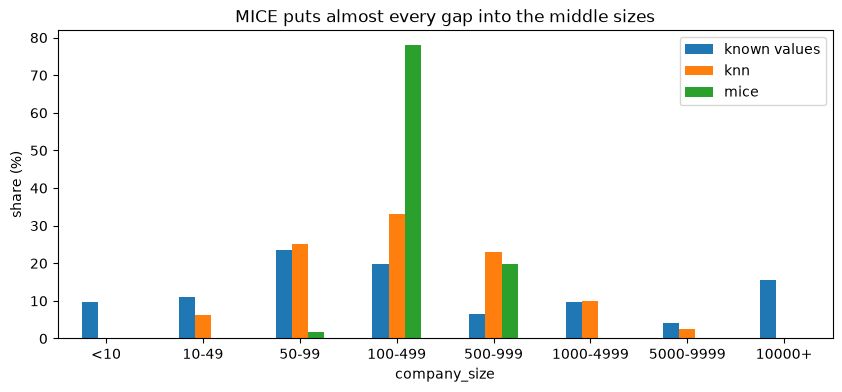

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
comparison.drop(index="Unknown")[["known values", "knn", "mice"]].plot.bar(ax=ax)
ax.set_title("MICE puts almost every gap into the middle sizes")
ax.set_ylabel("share (%)")
ax.tick_params(axis="x", rotation=0)
plt.show()

### Reading the result

- **mode:** all 4,714 gaps in the training data become "50-99". About 31 % of all students suddenly work in the same company size.
- **unknown:** every gap becomes "Unknown". Nothing is invented.
- **knn:** spreads the gaps over several sizes, mostly 50 to 999 employees. Looks more natural than mode, but the values are still guesses.
- **mice:** 78 % of the gaps end up in "100-499". MICE predicts a number for the code with a regression, and a regression likes to predict values close to the middle. After rounding, almost all of them land on the middle sizes. Very small and very big companies hardly appear.

**Result of check 1:** mode, knn and mice give every student a company size, even the ones who probably have no employer. Only "unknown" fits what the overview notebook found.

## 6. Check 2: is it useful?

### Why a model now?

We don't fill the gaps for their own sake. The filled data will be the input for the model that predicts job_change. So the best method is the one that keeps the most useful information for that model.

To test this, we train the same simple model on every filled version: logistic regression from the lecture (chapter 3). The model is only a **measuring tool** here, not our final model. Everything else stays the same (same model, same features, same folds), so any difference in the result can only come from the filling method.

The categories are one-hot encoded and the numbers are scaled with `StandardScaler`, the same way for all four versions.

### How we measure: ROC AUC

The model gives every student a probability that they change their job. ROC AUC measures how well these probabilities sort the students:

> Pick one student who changed the job and one who didn't, at random. AUC is the chance that the model gives the job changer the higher probability.

- 0.5 = coin flip, the model learned nothing
- 1.0 = perfect sorting

Why not accuracy? Only 25 % of the students change their job. A model that always says "no change" would already be 75 % correct while being completely useless. Its AUC would be 0.5.

### How we validate

5-fold cross-validation on the training data (lecture, chapter 3), with the same five folds for every method.

The filling has to happen inside every fold: learn on the four training folds, apply to the fifth. That's why the loop calls `impute` again in every round. If we filled everything once beforehand, the method would already have seen the validation data. A scikit-learn `Pipeline` would do this automatically, here we write it out so every step is visible.

In [42]:
def make_model():
    prepare = ColumnTransformer([
        ("categories", OneHotEncoder(handle_unknown="ignore"), make_column_selector(dtype_include="category")),
        ("numbers", StandardScaler(), make_column_selector(dtype_exclude="category")),
    ])
    return Pipeline([("prepare", prepare), ("model", LogisticRegression(max_iter=1000))])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = []

for method in methods:
    for fold, (train_idx, val_idx) in enumerate(cv.split(X_train, y_train), start=1):
        train_part, val_part = impute(method, X_train.iloc[train_idx], X_train.iloc[val_idx])

        model = make_model()
        model.fit(train_part, y_train.iloc[train_idx])
        probabilities = model.predict_proba(val_part)[:, 1]

        scores.append({
            "method": method,
            "fold": fold,
            "AUC": roc_auc_score(y_train.iloc[val_idx], probabilities),
        })

scores = pd.DataFrame(scores)
scores.groupby("method")["AUC"].agg(["mean", "std"]).round(3).sort_values("mean", ascending=False)

,mean,std
method,,
unknown,0.779,0.009
mice,0.765,0.008
mode,0.757,0.014
knn,0.752,0.009


In [43]:
# same folds for every method, so we can compare fold by fold
per_fold = scores.pivot(index="fold", columns="method", values="AUC").round(3)
per_fold

method,knn,mice,mode,unknown
fold,,,,
1,0.739,0.757,0.739,0.769
2,0.754,0.775,0.772,0.791
3,0.762,0.769,0.770,0.786
4,0.759,0.768,0.753,0.778
5,0.747,0.756,0.749,0.772


### Reading the result

| Method | AUC (mean ± std) |
|---|---|
| unknown | 0.779 ± 0.009 |
| mice | 0.765 ± 0.008 |
| mode | 0.757 ± 0.014 |
| knn | 0.752 ± 0.009 |

- **unknown is the best method, and in every single fold.** The difference to the others (0.014 to 0.027) is bigger than the spread between the folds (about 0.01), so it's not just luck.
- **Why?** This is exactly the finding from the overview notebook: job changers have missing company information twice as often. With "unknown" the model sees "company information missing" (after one-hot encoding it is its own 0/1 column) and can use it as a hint. With mode, knn and mice the model sees an invented company size instead, and the hint is gone.
- **knn is not better than mode**, even though it is much more effort. One reason could be the weak point from section 4: distances between codes of unordered columns mean nothing.
- All methods are clearly above 0.5, so the model learns something in every version.

**Result of check 2:** "unknown" keeps the most useful information.

### What this means for every column

| Column | Missing | Final solution | When | Why |
|---|---|---|---|---|
| company_type | 6,140 (32.0 %) | own category "Unknown" | now, before saving | gap often means "no employer" and is a hint for job_change (check 1 + check 2) |
| company_size | 5,938 (31.0 %) | own category "Unknown", order removed | now, before saving | same as company_type; "Unknown" has no place in the size order |
| major_discipline | 2,813 (14.7 %) | 1. "No Major" for Primary/High School (2,325)<br>2. "Unknown" for the rest (488) | now, before saving | 1. no degree = no major (fact, not a guess)<br>2. mostly students whose education_level is missing too |
| education_level | 460 (2.4 %) | most common value | later, in the model pipeline | few gaps, weak link to the target; learned from data → training part only |
| last_new_job | 423 (2.2 %) | most common value | later, in the model pipeline | same as education_level |
| enrolled_university | 386 (2.0 %) | most common value | later, in the model pipeline | same as education_level |
| experience | 65 (0.3 %) | most common value | later, in the model pipeline | very few gaps, no link found |
| gender | – | not filled, column dropped | now, before saving | not used in the model (fairness) |

**Rule behind the "When" column:** steps that don't learn anything from the data (a fixed rule, a new category) can be done on the whole dataset. Steps that learn something (the most common value) must be fitted on the training part only, otherwise test data leaks in.

## 7. Decision: why "unknown"?

The decision is not just "the highest number". All three steps point in the same direction:

| Reason | Evidence |
|---|---|
| Many gaps mean "no employer", not "forgot to fill in" | overview notebook: company information is missing about three times as often without relevant experience |
| "unknown" doesn't invent anything | check 1: mode, knn and mice give every student a company size, mice even puts 78 % into "100-499" |
| The gap is a hint for job_change, "unknown" keeps it | overview notebook: missing twice as often for job changers. Check 2: highest AUC, in every fold |
| Easy to explain | one extra category instead of a model that guesses values |

So the AUC in check 2 confirms what the overview notebook already suggested.

### What gets saved

We save the full dataset (all columns except gender, including student_id and city) with the steps that don't learn anything from the data:

- the rule for major_discipline ("No Major" for students without a degree)
- "Unknown" in company_type, company_size and major_discipline
- the gender column is dropped

The **small columns stay empty on purpose.** The most common value is something learned from the data, so it has to be calculated on the training part only, inside the model pipeline later (`SimpleImputer(strategy="most_frequent")`). If we filled them now, information from the later test set would leak into it.

In [44]:
prepared = df.drop(columns="gender")

school_only = prepared["education_level"].isin(["Primary School", "High School"])
prepared.loc[school_only & prepared["major_discipline"].isna(), "major_discipline"] = "No Major"

for col in big_cols:
    prepared[col] = prepared[col].cat.as_unordered().cat.add_categories("Unknown").fillna("Unknown")

print("Missing values left:")
print(prepared.isna().sum()[prepared.isna().sum() > 0])

Missing values left:
enrolled_university    386
education_level        460
experience              65
last_new_job           423
dtype: int64


Only education_level, last_new_job, enrolled_university and experience still have gaps (1,334 in total, all under 2.5 % per column). They are filled in section 8.

## 8. The last gaps: filling the small columns

Four columns still have gaps: education_level (460), last_new_job (423), enrolled_university (386) and experience (65). Together 1,334 gaps, all under 2.5 % per column.

### How we fill them

**With the most common value (mode).** With so few gaps the method hardly matters (section 4), and mode is the simplest one to explain.

### Why we have to split before filling

The test set plays the role of "new students we have never seen". So everything that is **learned from the data** may only come from the training part. The mode is learned: we count the values and take the most common one.

A small example with 10 students and education_level:

```
train (7):  Graduate, Graduate, Graduate, Masters, Masters, Masters, NaN
test  (3):  Masters, Masters, NaN
```

- **Wrong: fill first, then split.** The mode is counted over all 10 students: Masters 5×, Graduate 3× → the gap in the training part becomes **Masters**. The test students decided what goes into the training data.
- **Right: split first, then fill.** The mode is counted on the training part only: Graduate 3×, Masters 3×. On a tie pandas takes the first value in the category order → **Graduate**. The test set has no influence, it is "not there yet".

Different value, only because the test set was counted too. This is **data leakage** (lecture, chapter 2a + 3): information from the test set got into the training. The test result then looks better than it would be for really new students.

The same rule holds for everything that learns from data: mode, median, `StandardScaler`, KNN imputer, MICE.

**When is filling before the split allowed?** When nothing is learned. "No Major" and "Unknown" (section 7) are fixed rules, the same for every student no matter which other students are in the data. That's why they were applied to the whole dataset.

### The order

1. **Split first.** Same split as in section 3 (`test_size=0.2`, `stratify`, `random_state=42`), so the test set contains exactly the same students as before.
2. **Learn on the training part only.** `fill_mode` from section 4 calculates the most common value per column on the training part.
3. **Apply to both parts.** The test part gets the values from the training part, even if its own most common value would be different. A really new student would be filled the same way.
4. **Check:** no gaps left in either part.
5. **Save both parts separately.** The test set stays untouched until the final model.

One limit: inside a later cross-validation the mode was learned on all five training folds, so the validation fold has "seen" a tiny bit of itself. With under 2.5 % gaps per column this effect is very small. For the test set there is no leakage at all.

In [45]:
# 1. same split as in section 3 (same rows, same random_state)
train_final, test_final = train_test_split(
    prepared, test_size=0.2, stratify=prepared["job_change"], random_state=42
)

# 2. + 3. most common value learned on the training part, used for both parts
train_final, test_final = fill_mode(train_final, test_final, small_cols)

# 4. check: no gaps left
print(f"train: {train_final.shape}, missing: {train_final.isna().sum().sum()}")
print(f"test:  {test_final.shape}, missing: {test_final.isna().sum().sum()}")

# 5. save both parts separately
train_final.to_pickle("customer_train_final_train.pkl")
test_final.to_pickle("customer_train_final_test.pkl")

train: (15326, 13), missing: 0
test:  (3832, 13), missing: 0


## Next step: using the files for the models

The model notebooks start from the two saved files, not from the raw data. Both are complete, so there is nothing left to fill.

| File | Rows | Use |
|---|---|---|
| `customer_train_final_train.pkl` | 15,326 | train, compare and tune the models (kNN, logistic regression) with 5-fold CV |
| `customer_train_final_test.pkl` | 3,832 | **once**, at the very end, for the chosen model |

What every model notebook has to do:

1. **Load both files** with `pd.read_pickle`. Don't split again, the split is already done.
2. **Separate features and target:** `y = job_change`, `X` = everything else **without `student_id` and `city`** (section 1: the id means nothing, `city_development_index` already describes the city).
3. **Encoding and scaling go into a `Pipeline`** (`ColumnTransformer` with `OneHotEncoder` for the categories and `StandardScaler` for the numbers, like in section 6). The scaler learns mean and spread, so it is fitted inside every CV fold, never on all data.
4. **Compare and tune only on the training file** (`cross_val_score` / `GridSearchCV`, `StratifiedKFold`), report mean ± std and compare to the baseline (always "no change").
5. **Test set once:** fit the chosen model on the whole training file, then score it on the test file (confusion matrix, precision, recall, F1, ROC AUC from `predict_proba`). After that, no more changes to the model.